# SLAP-GRO — Phase 9 & 10: Genetic Route Optimization (GRO) Debugging & Visual Demo

Notebook này trình diễn và gỡ lỗi quy trình tối ưu hóa hành trình bằng thuật toán di truyền GRO:
1. **Baseline Route**: Đánh giá lộ trình ban đầu trước khi tối ưu (quãng đường chưa sắp xếp).
2. **GRO Optimization**: Tối ưu hóa thứ tự ghé thăm các vị trí nhặt hàng qua các thế hệ.
3. **Convergence Curve**: Vẽ đồ thị đường cong hội tụ (Best Fitness và Mean Fitness qua từng thế hệ).
4. **Visual Tour Map**: Vẽ so sánh trực quan sơ đồ tuyến đường di chuyển **Trước vs Sau tối ưu** trên mặt bằng kho 2D.
5. **Crossover Comparison**: So sánh hiệu năng giữa Mode B (Order Crossover - OX) và Mode A (Single-point Repair).


In [1]:
import sys, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path(os.getcwd()).resolve().parent if 'notebooks' in os.getcwd() else Path(os.getcwd()).resolve()
sys.path.insert(0, str(project_root / 'src'))

from slap_gro.warehouse import build_warehouse
from slap_gro.picking.wave import PickingWaveDataset
from slap_gro.picking.picking_points import build_gro_route_targets
from slap_gro.routing.distance import distance
from slap_gro.routing.route import route_distance
from slap_gro.gro import GROConfig, GROOptimizer, GROResult

# 1. Khởi tạo kho và nạp Wave
wh = build_warehouse('real')
dataset = PickingWaveDataset.from_csv()
target_wave_id = dataset.wave_ids[0]
wave = dataset.get(target_wave_id)
depot, pick_locations = build_gro_route_targets(wave, wh)
loc_ids = [loc.id for loc in pick_locations]

print(f'Mục tiêu tối ưu Wave #{target_wave_id}: {len(loc_ids)} điểm nhặt hàng xuất phát và kết thúc tại Depot.')


Mục tiêu tối ưu Wave #33168: 22 điểm nhặt hàng xuất phát và kết thúc tại Depot.


In [1]:
# 2. Cấu hình và chạy GRO Optimizer
# Thiết lập debug: population=100, iterations=150, T=3, Pc=0.90, Pm=0.10
def dist_fn(u: str, v: str) -> float:
    loc_u = wh.get_depot() if u == 'DEPOT' else wh.get_location(u)
    loc_v = wh.get_depot() if v == 'DEPOT' else wh.get_location(v)
    return distance(loc_u, loc_v, method='euclidean')

config = GROConfig(
    population_size=100,
    iterations=150,
    tournament_size=3,
    crossover_rate=0.90,
    mutation_rate=0.10,
    crossover_method='ox',       # Mode B: Permutation-safe OX
    mutation_method='inversion', # 2-opt inversion move
    elitism=True,
    random_seed=42,
    verbose=False,
)

optimizer = GROOptimizer(config=config, distance_fn=dist_fn, depot_id='DEPOT')
result = optimizer.optimize(loc_ids)

print(result.summary())


GRO Result Summary:
  - Initial Distance : 6653.27 m
  - Optimized Distance: 4177.30 m
  - Improvement       : 2475.97 m (37.21%)
  - Route Stops       : 24 stops (22 picks)
  - Iterations        : 150
  - Execution Time    : 0.667 s


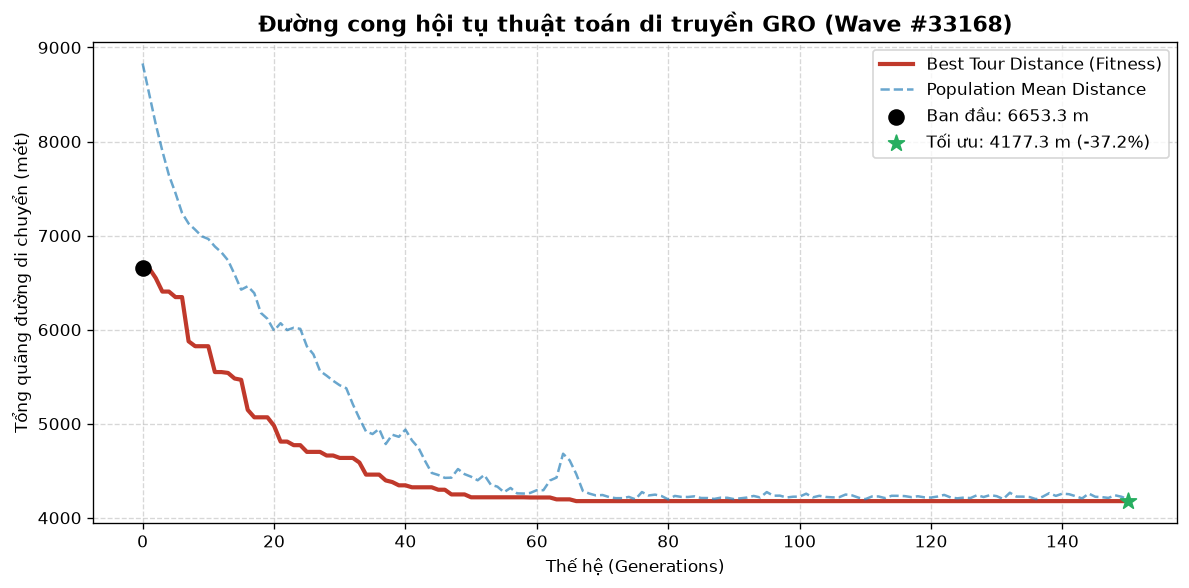

In [1]:
# 3. Vẽ biểu đồ đường cong hội tụ (Convergence Curve)
fig, ax = plt.subplots(figsize=(10, 5))
gens = range(len(result.history_best_fitness))

ax.plot(gens, result.history_best_fitness, color='#c0392b', linewidth=2.5, label='Best Tour Distance (Fitness)')
ax.plot(gens, result.history_mean_fitness, color='#2980b9', linewidth=1.5, linestyle='--', alpha=0.7, label='Population Mean Distance')

# Điểm bắt đầu và kết thúc
ax.scatter([0], [result.initial_distance], color='black', s=80, zorder=5, label=f'Ban đầu: {result.initial_distance:.1f} m')
ax.scatter([result.iterations_run], [result.best_distance], color='#27ae60', s=100, marker='*', zorder=5, label=f'Tối ưu: {result.best_distance:.1f} m (-{result.improvement_pct:.1f}%)')

ax.set_title('Đường cong hội tụ thuật toán di truyền GRO (Wave #33168)', fontsize=13, fontweight='bold')
ax.set_xlabel('Thế hệ (Generations)')
ax.set_ylabel('Tổng quãng đường di chuyển (mét)')
ax.legend(frameon=True)
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


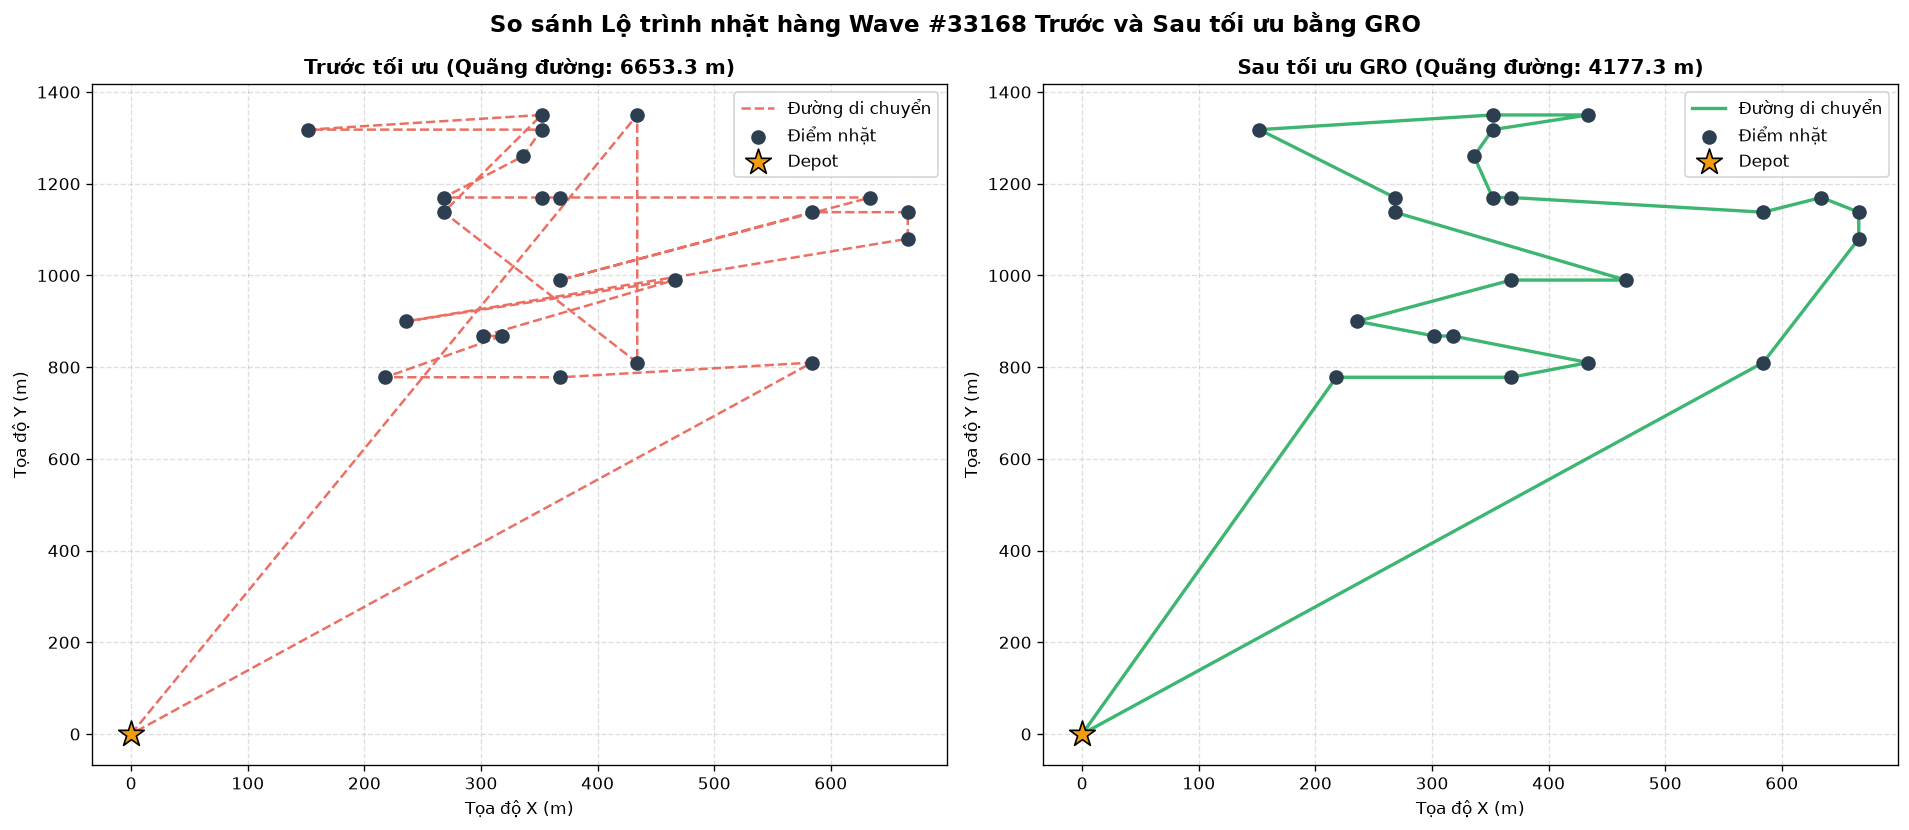

In [1]:
# 4. Trực quan hóa so sánh lộ trình Trước vs Sau tối ưu trên mặt bằng 2D
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Lấy tọa độ danh sách các điểm cho lộ trình ban đầu và lộ trình tối ưu
def get_route_coords(stop_ids):
    xs, ys = [], []
    for sid in stop_ids:
        loc = wh.get_depot() if sid == 'DEPOT' else wh.get_location(sid)
        xs.append(loc.x)
        ys.append(loc.y)
    return xs, ys

init_stops = ['DEPOT'] + loc_ids + ['DEPOT']
opt_stops = result.best_route

init_x, init_y = get_route_coords(init_stops)
opt_x, opt_y = get_route_coords(opt_stops)

# Sơ đồ 1: Tuyến đường ban đầu (Chưa tối ưu)
axes[0].plot(init_x, init_y, color='#e74c3c', linestyle='--', linewidth=1.5, alpha=0.8, label='Đường di chuyển')
axes[0].scatter(init_x[1:-1], init_y[1:-1], color='#2c3e50', s=60, zorder=4, label='Điểm nhặt')
axes[0].scatter([depot.x], [depot.y], color='#f39c12', marker='*', s=260, edgecolors='black', zorder=5, label='Depot')
axes[0].set_title(f'Trước tối ưu (Quãng đường: {result.initial_distance:.1f} m)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Tọa độ X (m)')
axes[0].set_ylabel('Tọa độ Y (m)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.4)

# Sơ đồ 2: Tuyến đường sau khi GRO tối ưu
axes[1].plot(opt_x, opt_y, color='#27ae60', linewidth=2.0, alpha=0.9, label='Đường di chuyển')
axes[1].scatter(opt_x[1:-1], opt_y[1:-1], color='#2c3e50', s=60, zorder=4, label='Điểm nhặt')
axes[1].scatter([depot.x], [depot.y], color='#f39c12', marker='*', s=260, edgecolors='black', zorder=5, label='Depot')
axes[1].set_title(f'Sau tối ưu GRO (Quãng đường: {result.best_distance:.1f} m)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Tọa độ X (m)')
axes[1].set_ylabel('Tọa độ Y (m)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.suptitle('So sánh Lộ trình nhặt hàng Wave #33168 Trước và Sau tối ưu bằng GRO', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


Mode B (OX): Best = 4834.71 m, Time = 0.55s
Mode A (Repair): Best = 4299.31 m, Time = 0.46s


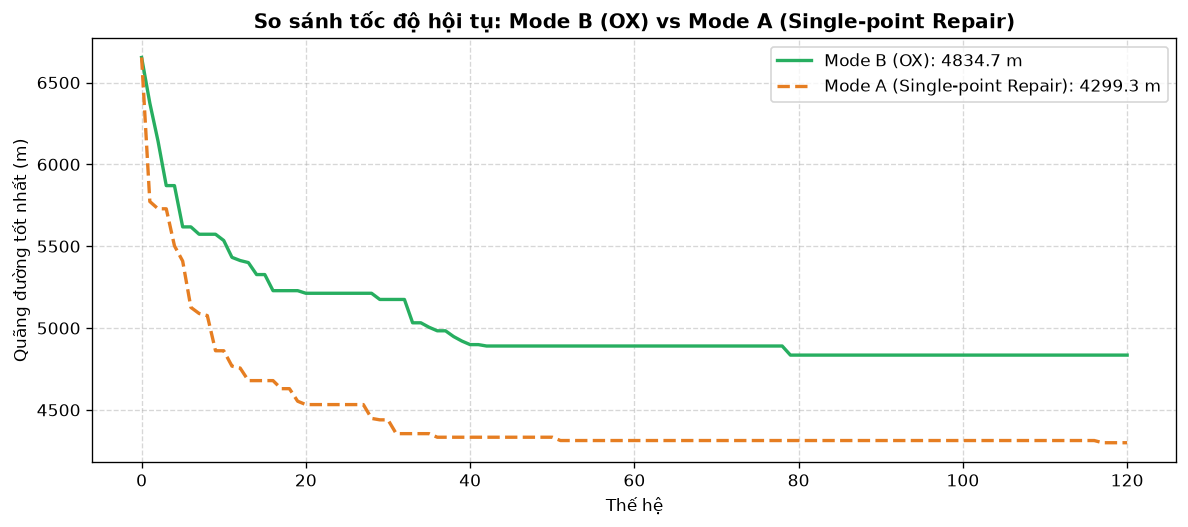

In [1]:
# 5. So sánh hiệu năng giữa Mode B (Order Crossover - OX) và Mode A (Single-point Repair)
cfg_ox = GROConfig(population_size=100, iterations=120, crossover_method='ox', random_seed=42)
cfg_repair = GROConfig(population_size=100, iterations=120, crossover_method='single_point_repair', random_seed=42)

res_ox = GROOptimizer(config=cfg_ox, distance_fn=dist_fn, depot_id='DEPOT').optimize(loc_ids)
res_repair = GROOptimizer(config=cfg_repair, distance_fn=dist_fn, depot_id='DEPOT').optimize(loc_ids)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(res_ox.history_best_fitness, label=f'Mode B (OX): {res_ox.best_distance:.1f} m', color='#27ae60', linewidth=2)
ax.plot(res_repair.history_best_fitness, label=f'Mode A (Single-point Repair): {res_repair.best_distance:.1f} m', color='#e67e22', linewidth=2, linestyle='--')
ax.set_title('So sánh tốc độ hội tụ: Mode B (OX) vs Mode A (Single-point Repair)', fontsize=12, fontweight='bold')
ax.set_xlabel('Thế hệ')
ax.set_ylabel('Quãng đường tốt nhất (m)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print(f'Mode B (OX): Best = {res_ox.best_distance:.2f} m, Time = {res_ox.execution_time_seconds:.2f}s')
print(f'Mode A (Repair): Best = {res_repair.best_distance:.2f} m, Time = {res_repair.execution_time_seconds:.2f}s')
